# 05 — Native-Grid MPAS-Seaice Initial Condition Comparisons (`mosaic`)

**One branch per run**: set `EVAL_BRANCH` in the configuration cell to `"clim"`, `"obs"` (ERA5), or `"obs_era5land_nsidc"` (ERA5-Land + NOAA/NSIDC). Figures and tables go to `DIAG_ROOT/<EVAL_BRANCH>/`.


This notebook uses [`mosaic`](https://docs.e3sm.org/mosaic/) (`mosaic.Descriptor` + `mosaic.polypcolor`) to render **MPAS-Seaice** initial conditions directly on the unstructured `IcoswISC30E3r5` polygons (`nCells = 235,160`) in North and South Polar Stereographic projections.

All helper functions live in [`util/ic_eval.py`](util/ic_eval.py), and figures are saved to `/global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/figure/`.

### Contents
1. **Build `mosaic.Descriptor` objects** for NH and SH polar projections
2. **State & difference maps (`Actual 2015`, each branch, and each branch `- 2015`; branches `clim`, `obs` (ERA5), `obs_era5land_nsidc` (ERA5-Land + NOAA/NSIDC))** for NH/SH ice concentration, ice thickness, and snow on ice
3. **Standardized anomaly ($z$) maps** on the native MPAS mesh
4. **4-season NH & SH sea-ice concentration comparison** across all four 2015 dates

In [1]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path("util").resolve()))
import importlib
import clim_restart
import ic_eval as ice

# Reload so edits to util/ take effect without restarting the kernel.
importlib.reload(clim_restart)
ice = importlib.reload(ice)
from clim_restart import source_file

ice.ensure_proj_data()
plt.rcParams["figure.dpi"] = 120

# Branch evaluated in this run: "clim", "obs" (ERA5), or "obs_era5land_nsidc".
# Figures and tables go to DIAG_ROOT/<EVAL_BRANCH>/.
EVAL_BRANCH = "obs_era5land_nsidc"

SRC_ROOT     = Path("/global/cfs/cdirs/e3sm/zhan391/v3.LR.S2D.ENSINT/BruteForce")
# Observation sets for the obs branches (as in 02_build_climatology_ic.ipynb);
# "label" names each set's observed anomaly in the maps.
ERA5_DIR     = Path("/global/cfs/projectdirs/m3522/cmip6/ERA5/e5.oper.an.sfc")
OBS_DATA     = Path("/global/cfs/cdirs/e3sm/zhan391/data")
OBS_SETS = {
    "obs": {
        "label": "ERA5",
        "root": {"elm": ERA5_DIR, "mpassi": ERA5_DIR},
        "fields": {"elm": ["sd", "swvl1", "swvl2-4", "stl1", "stl2-4"], "mpassi": ["ci"]},
    },
    "obs_era5land_nsidc": {
        "label": "ERA5-Land/NSIDC",
        "root": {"elm": OBS_DATA / "ERA5_LND", "mpassi": OBS_DATA / "NOAA_NSIDC"},
        "fields": {"elm": ["sd", "swvl1", "swvl2-4", "stl1", "stl2-4"], "mpassi": ["ci"]},
    },
}
BRANCHES     = [EVAL_BRANCH]
OBS_REFS     = {b: s["label"] for b, s in OBS_SETS.items() if b == EVAL_BRANCH}   # obs branch -> observed-anomaly label
OUT_ROOT     = Path("/global/cfs/cdirs/e3sm/S2S2D/RTENSO2026/initial_conditions")
CACHE_DIR    = OUT_ROOT / "cache"
DIAG_ROOT    = Path("/global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic") / EVAL_BRANCH
SAVE_DIAG    = True

TEST_DATES   = ["2015-02-01", "2015-05-01", "2015-08-01", "2015-11-01"]
EXAMPLE_DATE = "2015-02-01"
BOX          = (15.0, 30.0)   # as in 02 (from 01_choose_box_size.ipynb)
BOX_SHIFTS   = 4             # as in 02 (selection distance only)
FIRST_YEAR   = 1995          # candidate years FIRST_YEAR-2018, as in 02 (None = 1980)

plans, distances, selections = ice.load_test_selections(
    TEST_DATES, SRC_ROOT, OUT_ROOT, obs_sets=OBS_SETS, branches=BRANCHES, first_year=FIRST_YEAR,
    box=BOX, box_shifts=BOX_SHIFTS, cache_dir=CACHE_DIR
)
obs_plans_ex = {label: plans[b, EXAMPLE_DATE] for b, label in OBS_REFS.items() if (b, EXAMPLE_DATE) in plans}

sample_ice_path = source_file(SRC_ROOT, "20251024_s2d_spinup", "mpassi", 2015, EXAMPLE_DATE[5:])
mpassi_desc = ice.build_mpassi_descriptors(sample_ice_path)
print("Loaded MPAS-Seaice mesh:", sample_ice_path.name)

Loaded MPAS-Seaice mesh: 20251024_s2d_spinup.mpassi.rst.2015-02-01_00000.nc


## 1. Native-Mesh State and Difference Maps (`EXAMPLE_DATE`)

For each MPAS-Seaice key field (NH top row, SH bottom row), in physical units:
1. **Reference**: the actual E3SM state on the date (the real 2015 BruteForce restart).
2. **Selected initial condition**: the E3SM state of the year chosen by the selection (`EVAL_BRANCH`), with
   PCC and RMSE against the reference.
3. **Error**: selected initial condition minus reference (bias and box PCC in the title).


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/obs_era5land_nsidc/figure/mpassi_state_diff_ice_concentration_20150201.png


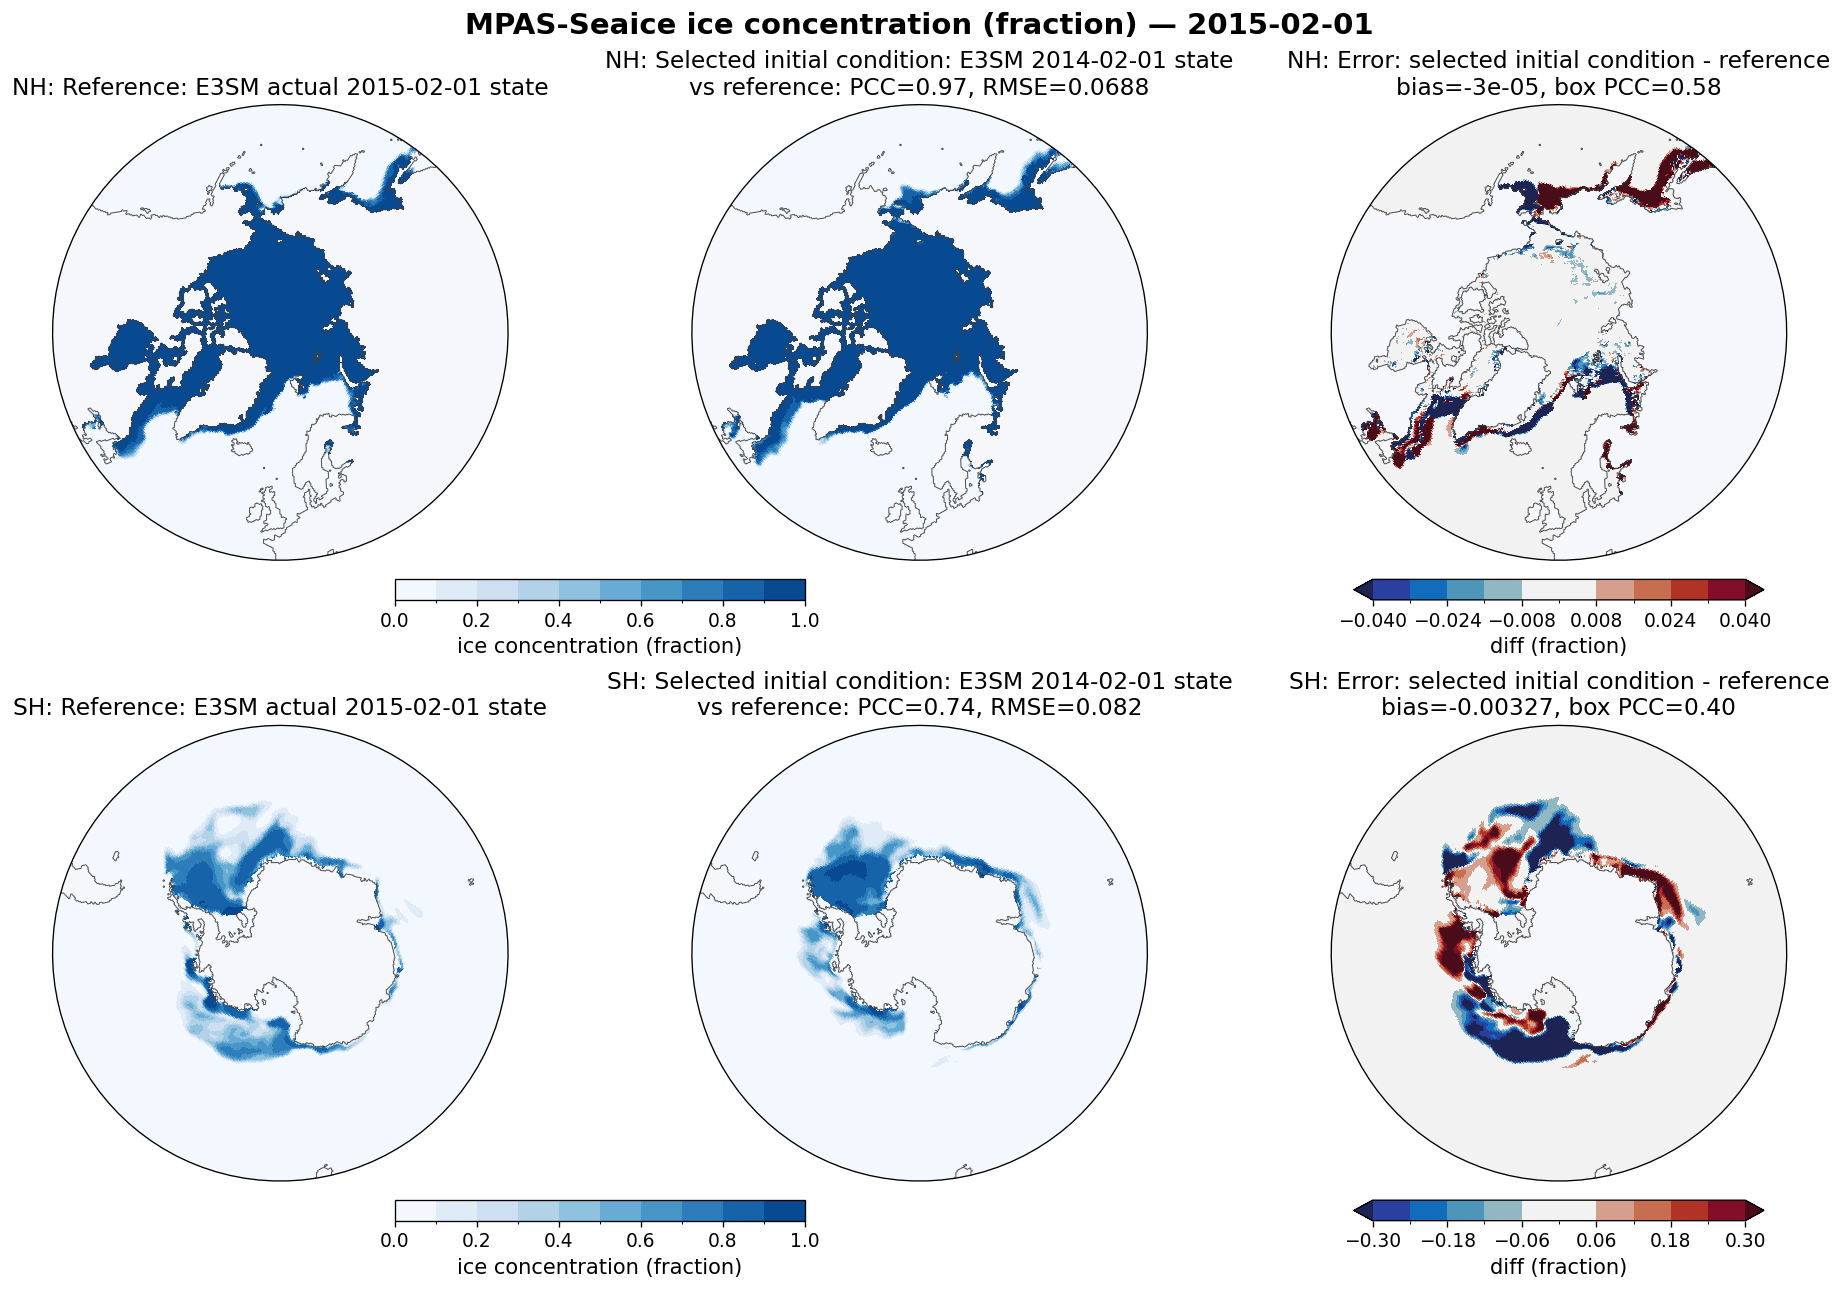

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/obs_era5land_nsidc/figure/mpassi_state_diff_ice_thickness_20150201.png


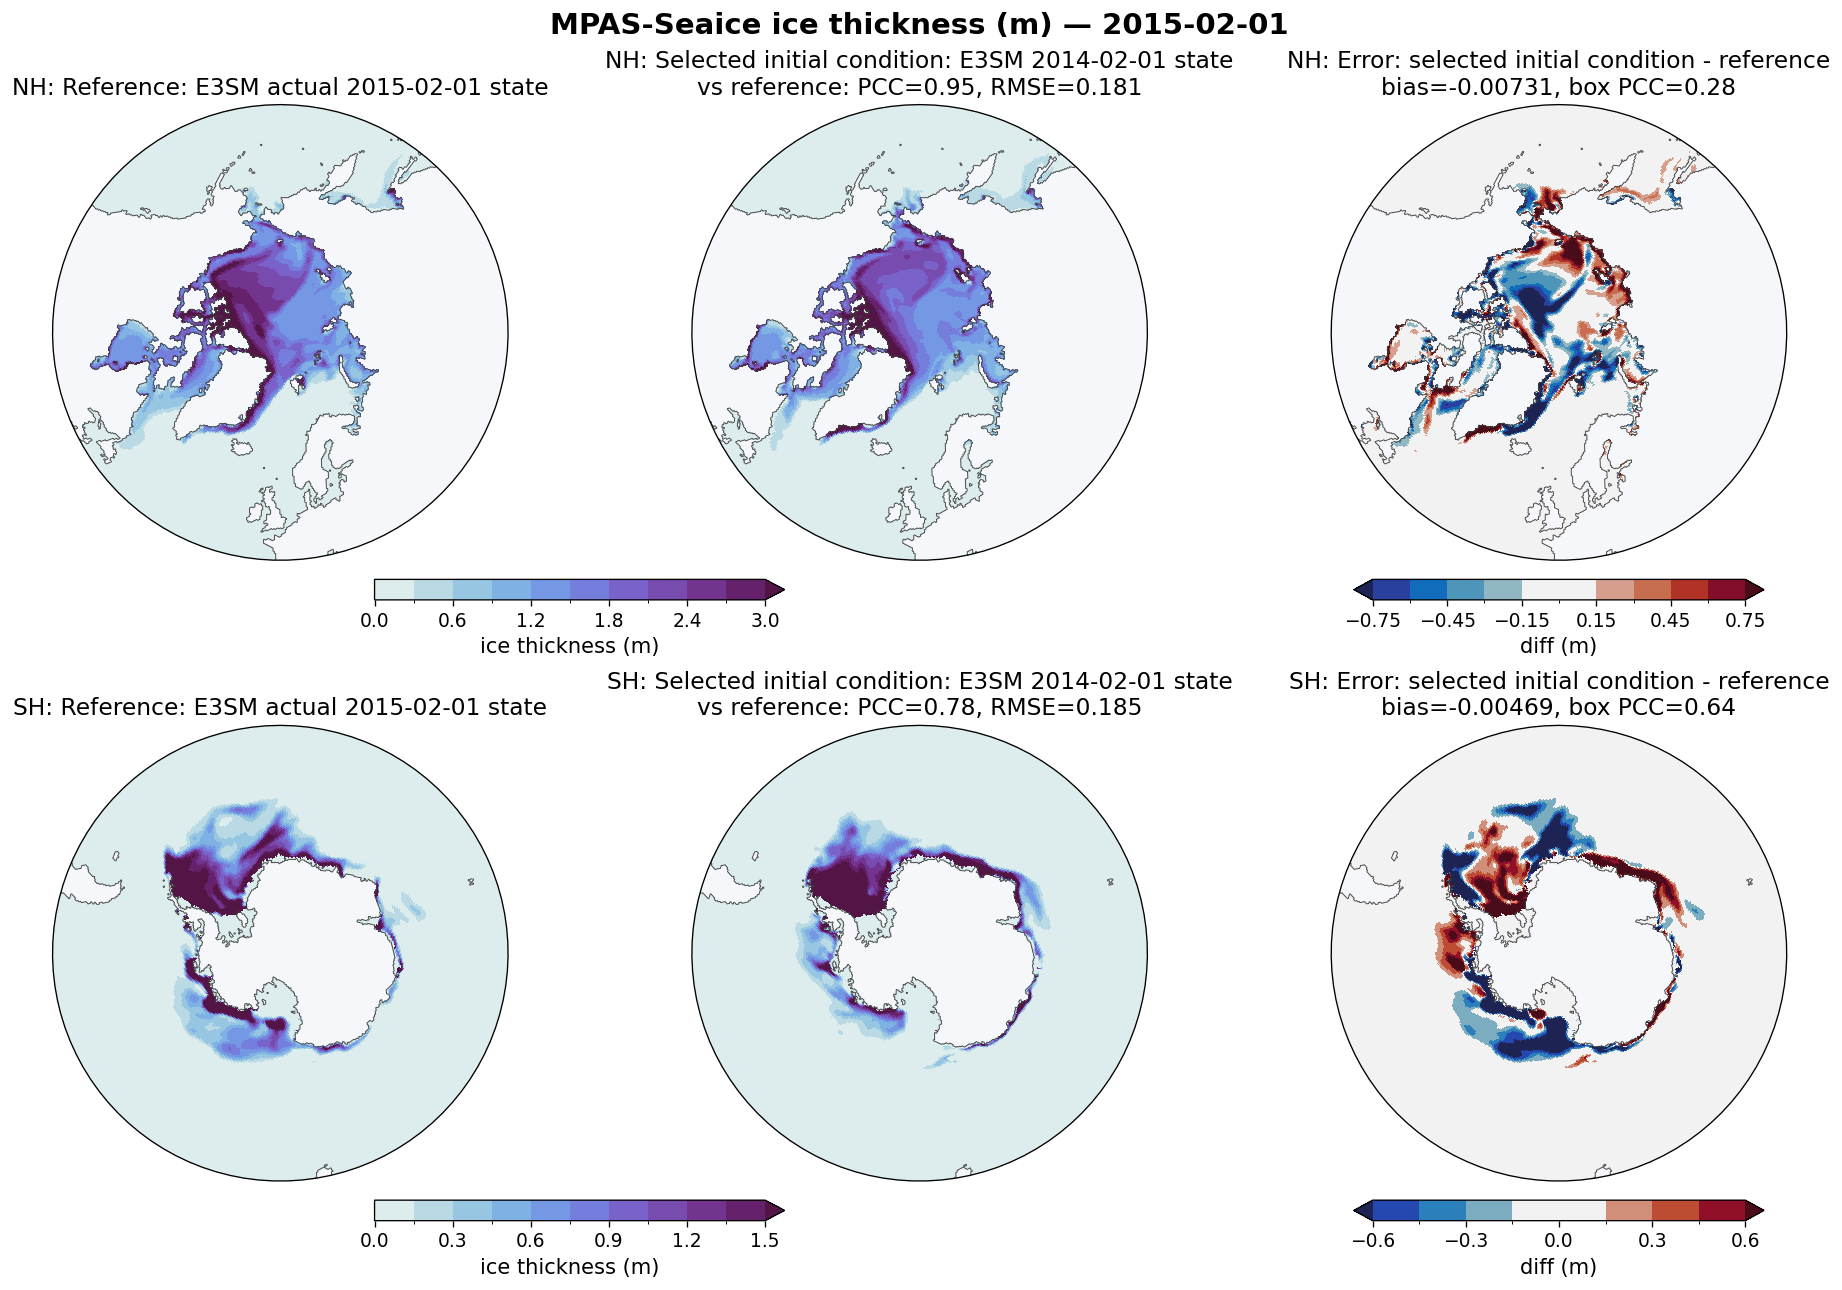

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/obs_era5land_nsidc/figure/mpassi_state_diff_snow_on_ice_20150201.png


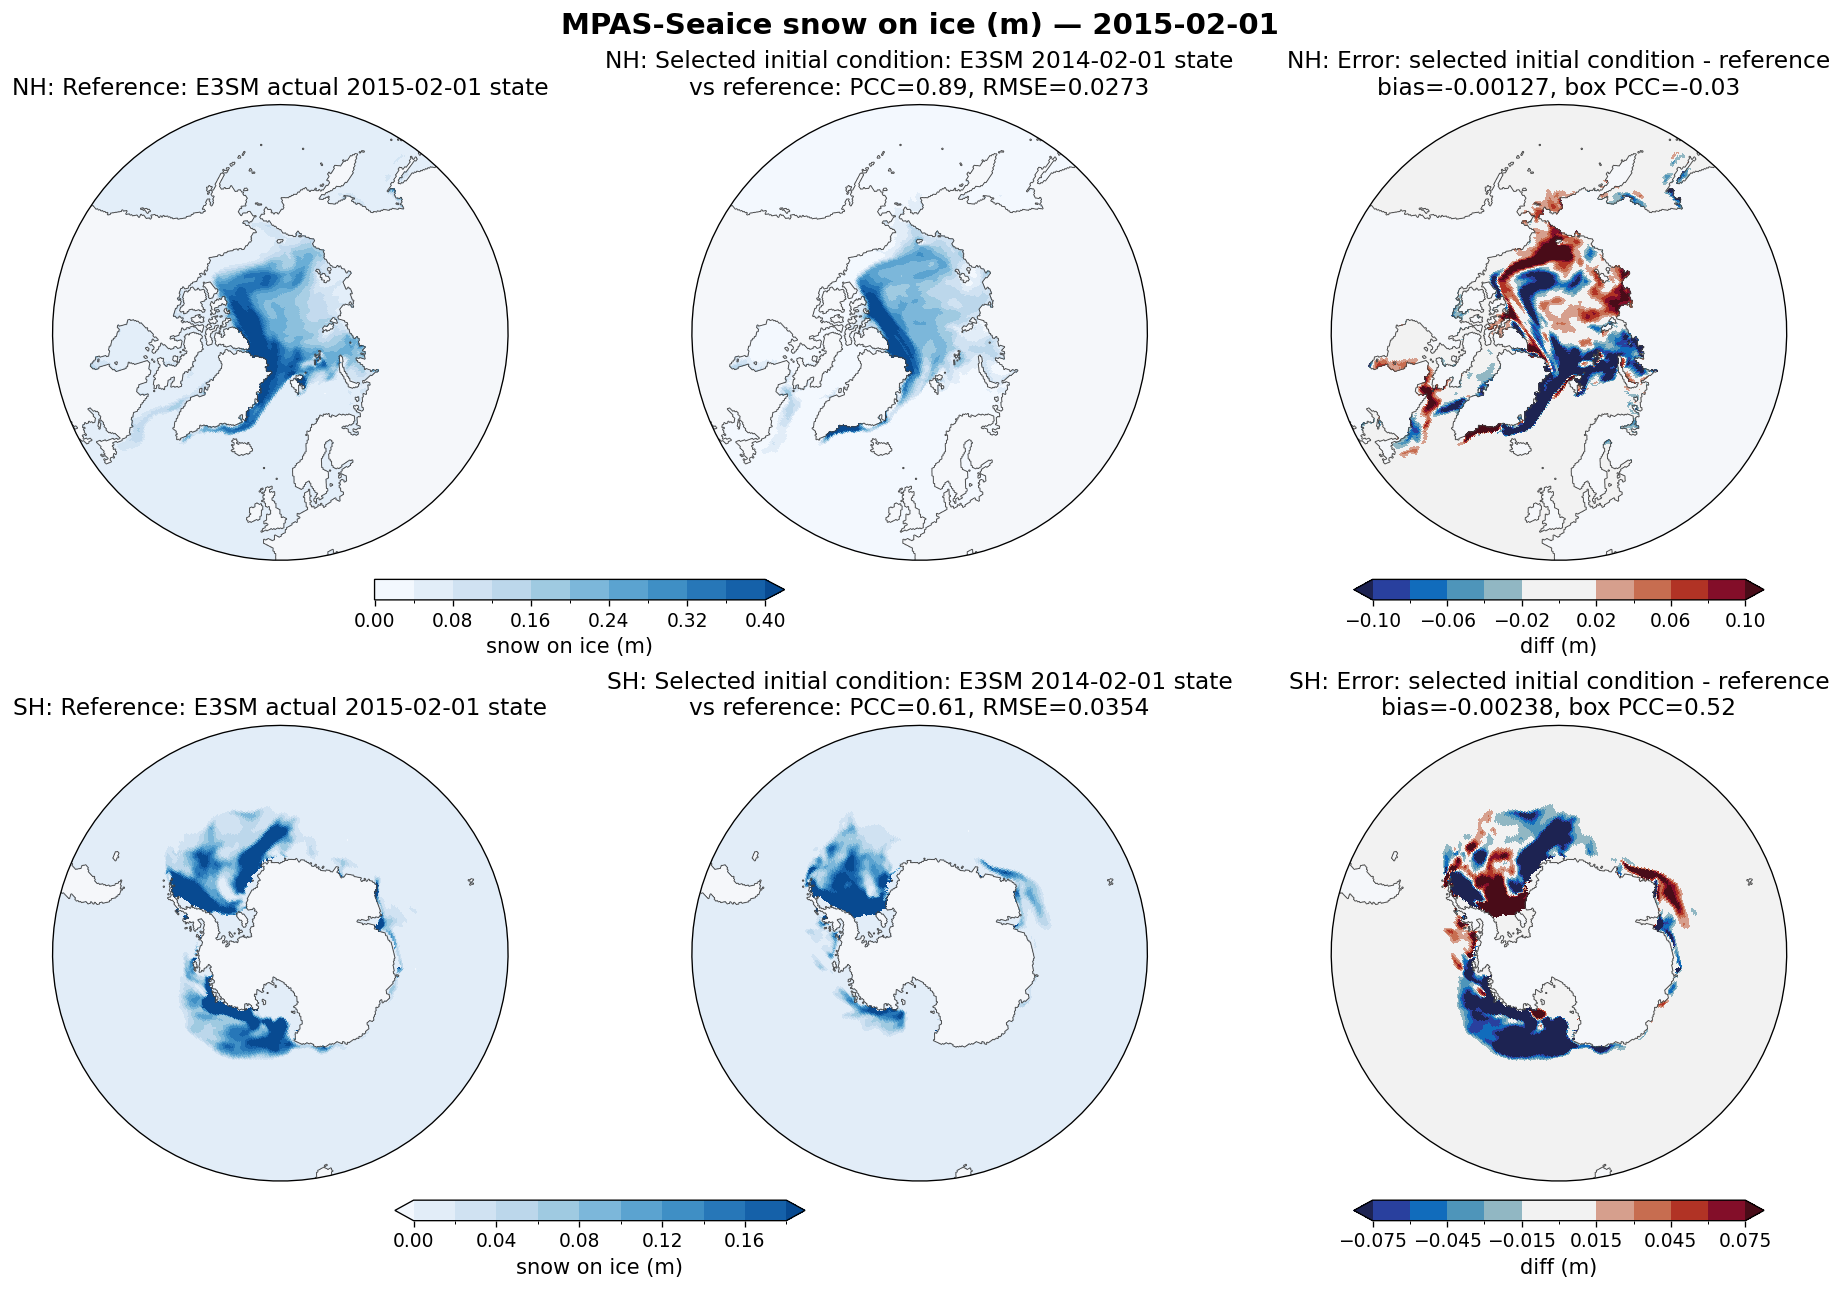

In [2]:
# --- Figure setup ---
FONTSIZE = 14        # panel-title font size; titles, labels, and ticks scale from it
PANEL_SIZE = None    # (width, height) of each panel in inches; None scales with FONTSIZE
DPI = 150            # resolution of the saved PNG

plan_ex = plans[EVAL_BRANCH, EXAMPLE_DATE]
byears_ex = {b: selections[b, EXAMPLE_DATE]["mpassi"] for b in BRANCHES if (b, EXAMPLE_DATE) in selections}

QUANTITIES = ["ice concentration", "ice thickness", "snow on ice"]   # each plotted for NH and SH

spatial_mpassi = {}
for quantity in QUANTITIES:
    for hemi in ("NH", "SH"):
        fname = f"{hemi} {quantity}"
        spatial_mpassi[fname] = ice.prepare_spatial_field(
            plan_ex, "mpassi", fname, 2015, byears_ex, obs_plans=obs_plans_ex, box=BOX, cache_dir=CACHE_DIR,
            log=lambda *_: None,
        )
    fig = ice.plot_mpassi_spatial(
        [spatial_mpassi[f"NH {quantity}"], spatial_mpassi[f"SH {quantity}"]], mpassi_desc, kind="state_and_diff",
        fontsize=FONTSIZE, panel_size=PANEL_SIZE,
    )
    ice.save_fig(
        fig, f"mpassi_state_diff_{ice.slugify(quantity)}_{EXAMPLE_DATE.replace('-', '')}",
        DIAG_ROOT, SAVE_DIAG, dpi=DPI,
    )
    plt.show()

## 2. Standardized Anomaly ($z$) Maps on the Native MPAS Mesh

Columns (all standardized anomalies z: anomaly from the 1995-2018 candidate-year mean for the same date,
divided by the field's typical interannual spread):
1. **Truth: observed anomaly** on the date (ERA5-Land for land, NOAA/NSIDC CDR for sea ice), relative to the
   observations' own climatology.
2. **Reference: E3SM actual state** on the date (the real 2015 BruteForce restart).
3. **Selected initial condition**: the E3SM state of the year chosen by matching the observation.

PCC (pattern correlation), RMSE (in z units), and box PCC (on 15x30 boxes) compare columns 2 and 3 with the
truth (column 1): how close the actual model state and the selected initial condition are to the observed
anomaly. Fields without an observation (sea-ice thickness, snow on ice) use the actual state as the truth.


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/obs_era5land_nsidc/figure/mpassi_z_ice_concentration_20150201.png


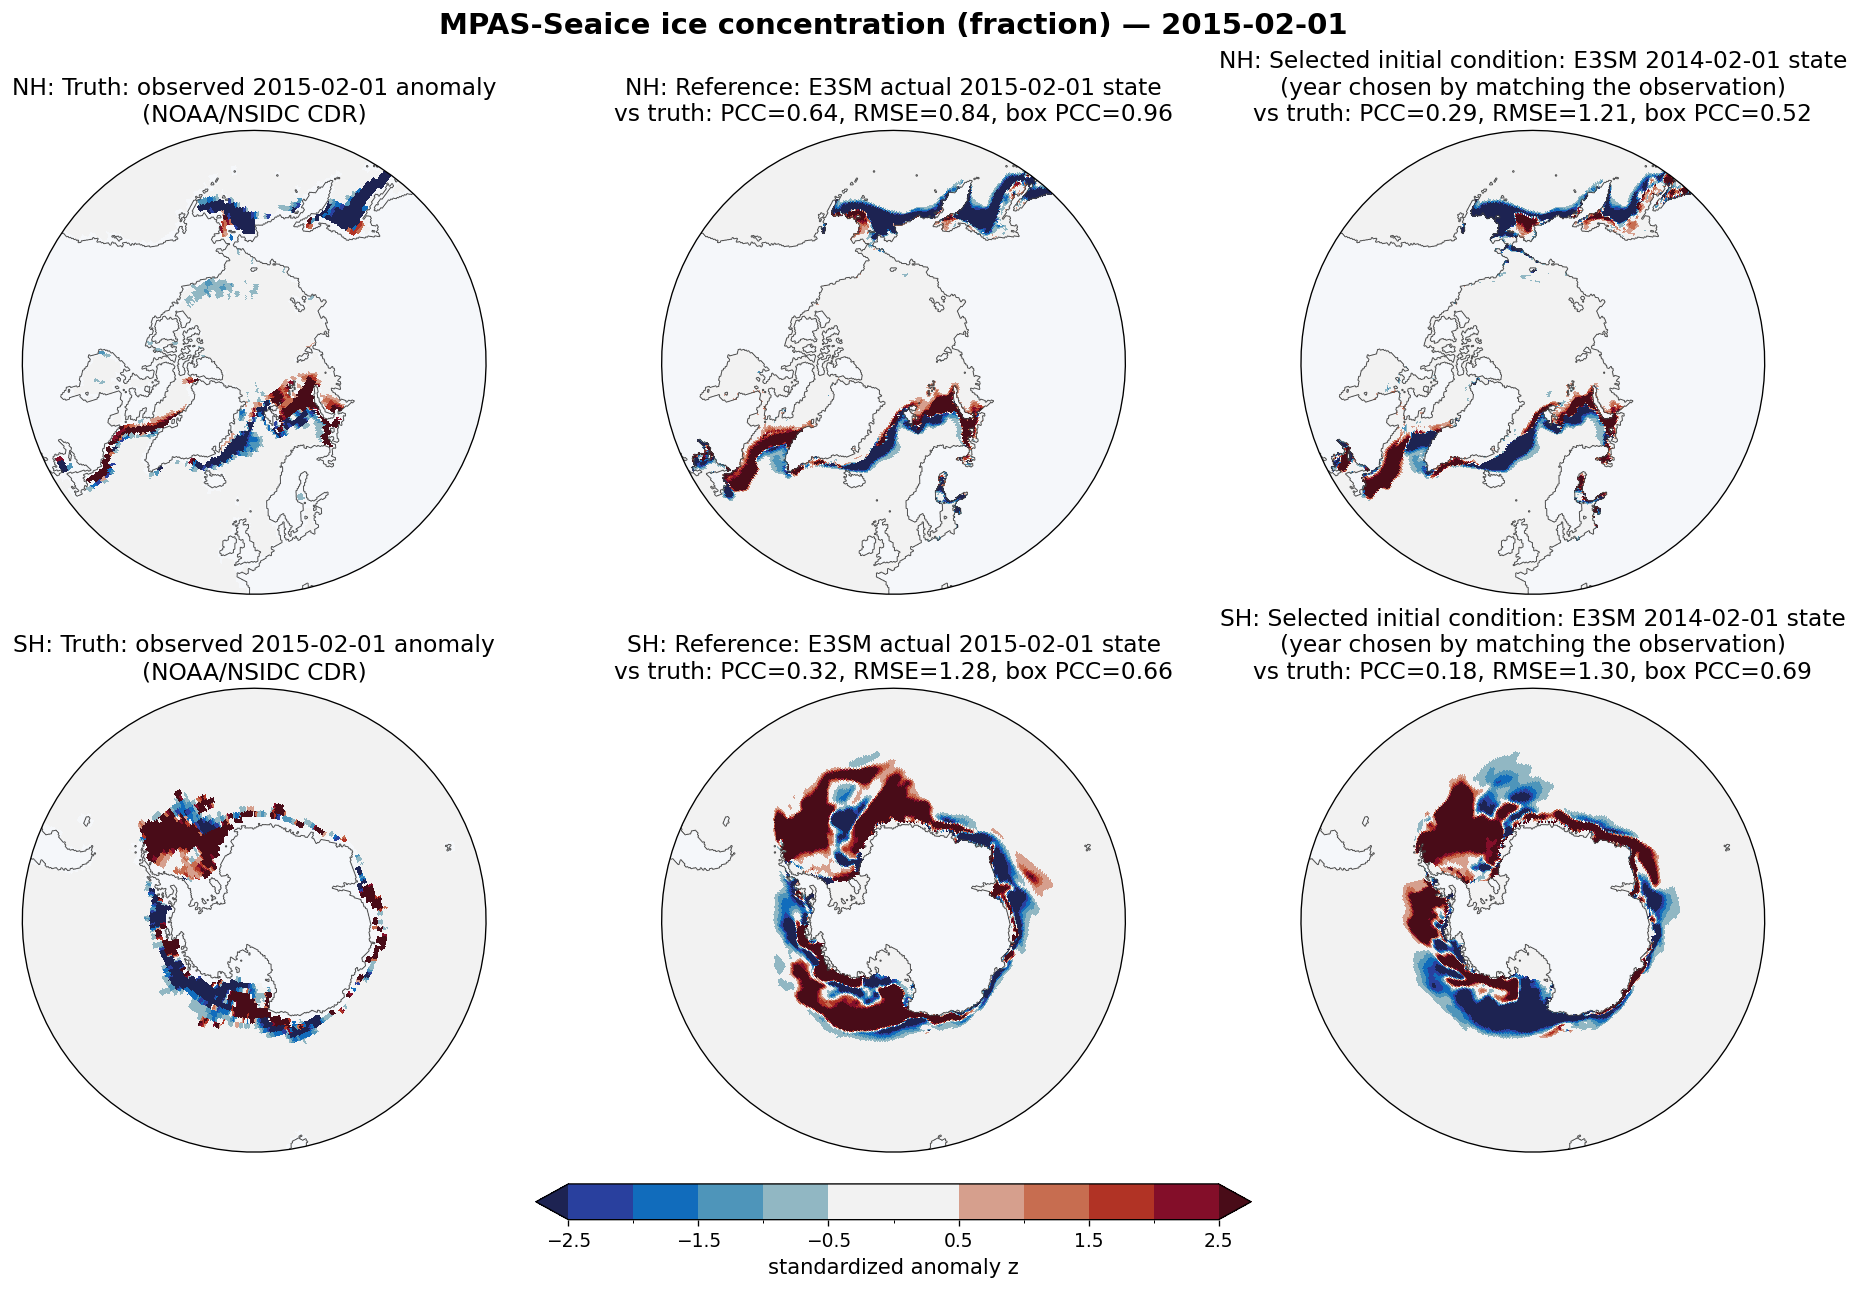

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/obs_era5land_nsidc/figure/mpassi_z_ice_thickness_20150201.png


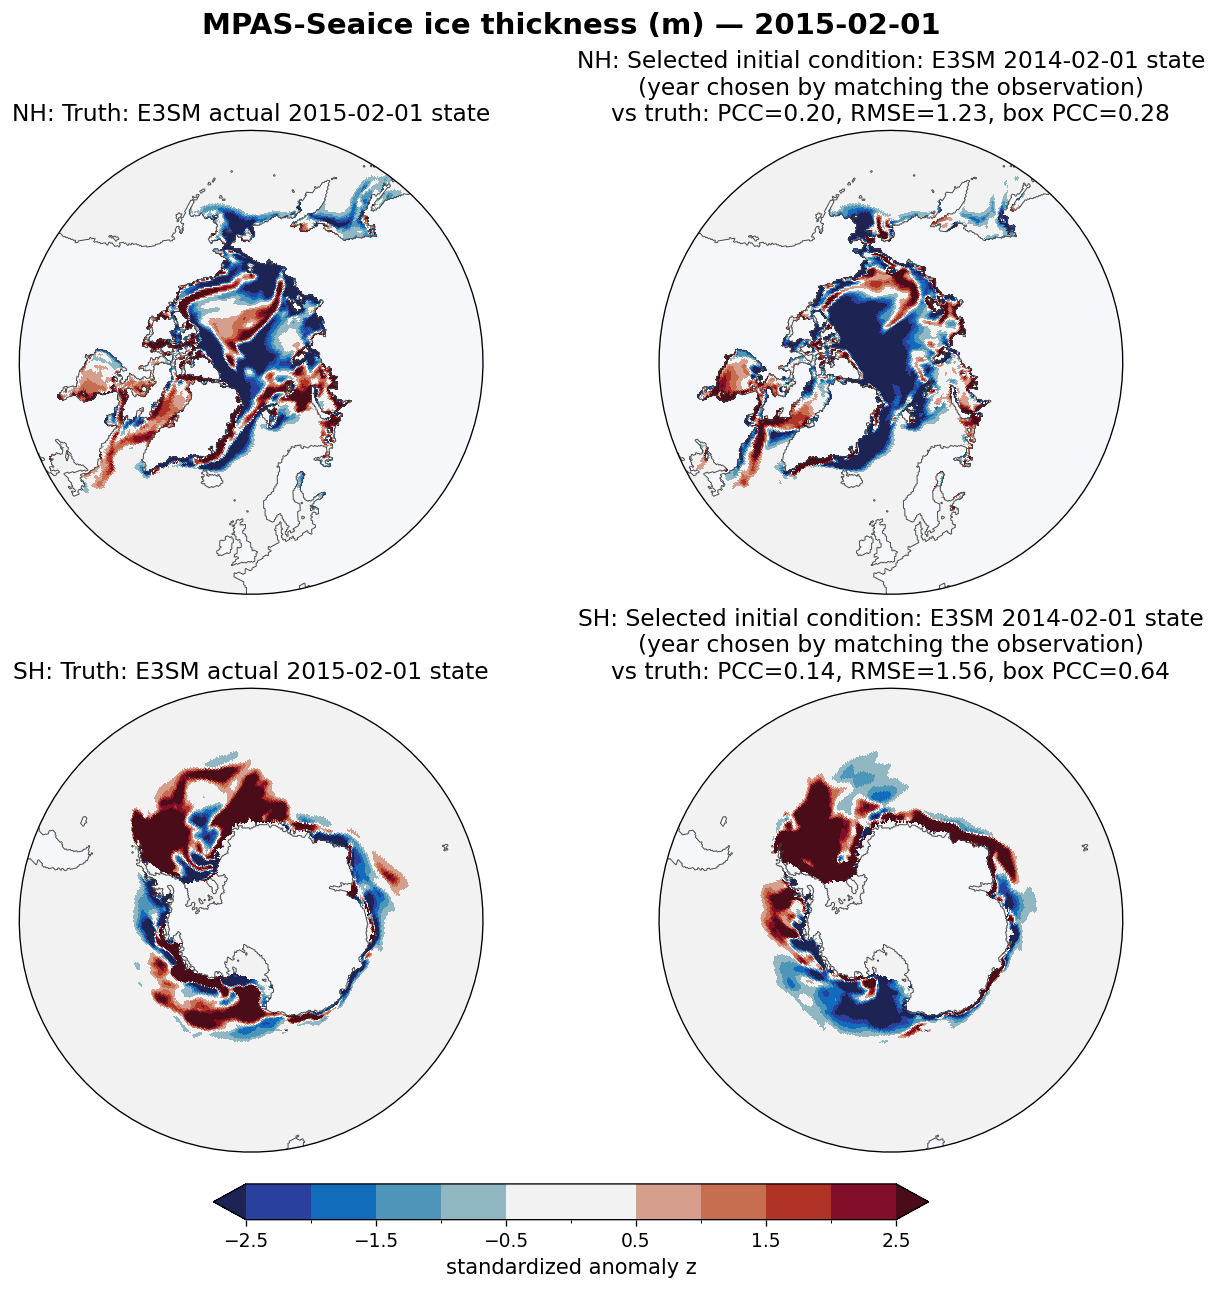

In [3]:
# --- Figure setup ---
FONTSIZE = 14        # panel-title font size; titles, labels, and ticks scale from it
PANEL_SIZE = None    # (width, height) of each panel in inches; None scales with FONTSIZE
DPI = 150            # resolution of the saved PNG
Z_LIM = 2.5          # color range of the standardized anomaly (z) maps

for quantity in ["ice concentration", "ice thickness"]:
    fig = ice.plot_mpassi_spatial(
        [spatial_mpassi[f"NH {quantity}"], spatial_mpassi[f"SH {quantity}"]], mpassi_desc, kind="z", z_lim=Z_LIM,
        fontsize=FONTSIZE, panel_size=PANEL_SIZE,
    )
    ice.save_fig(
        fig, f"mpassi_z_{ice.slugify(quantity)}_{EXAMPLE_DATE.replace('-', '')}",
        DIAG_ROOT, SAVE_DIAG, dpi=DPI,
    )
    plt.show()

## 3. Four-Season MPAS-Seaice Comparison (`2015-02-01` to `2015-11-01`)

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/obs_era5land_nsidc/figure/mpassi_4seasons_nh_ice_concentration_2015.png


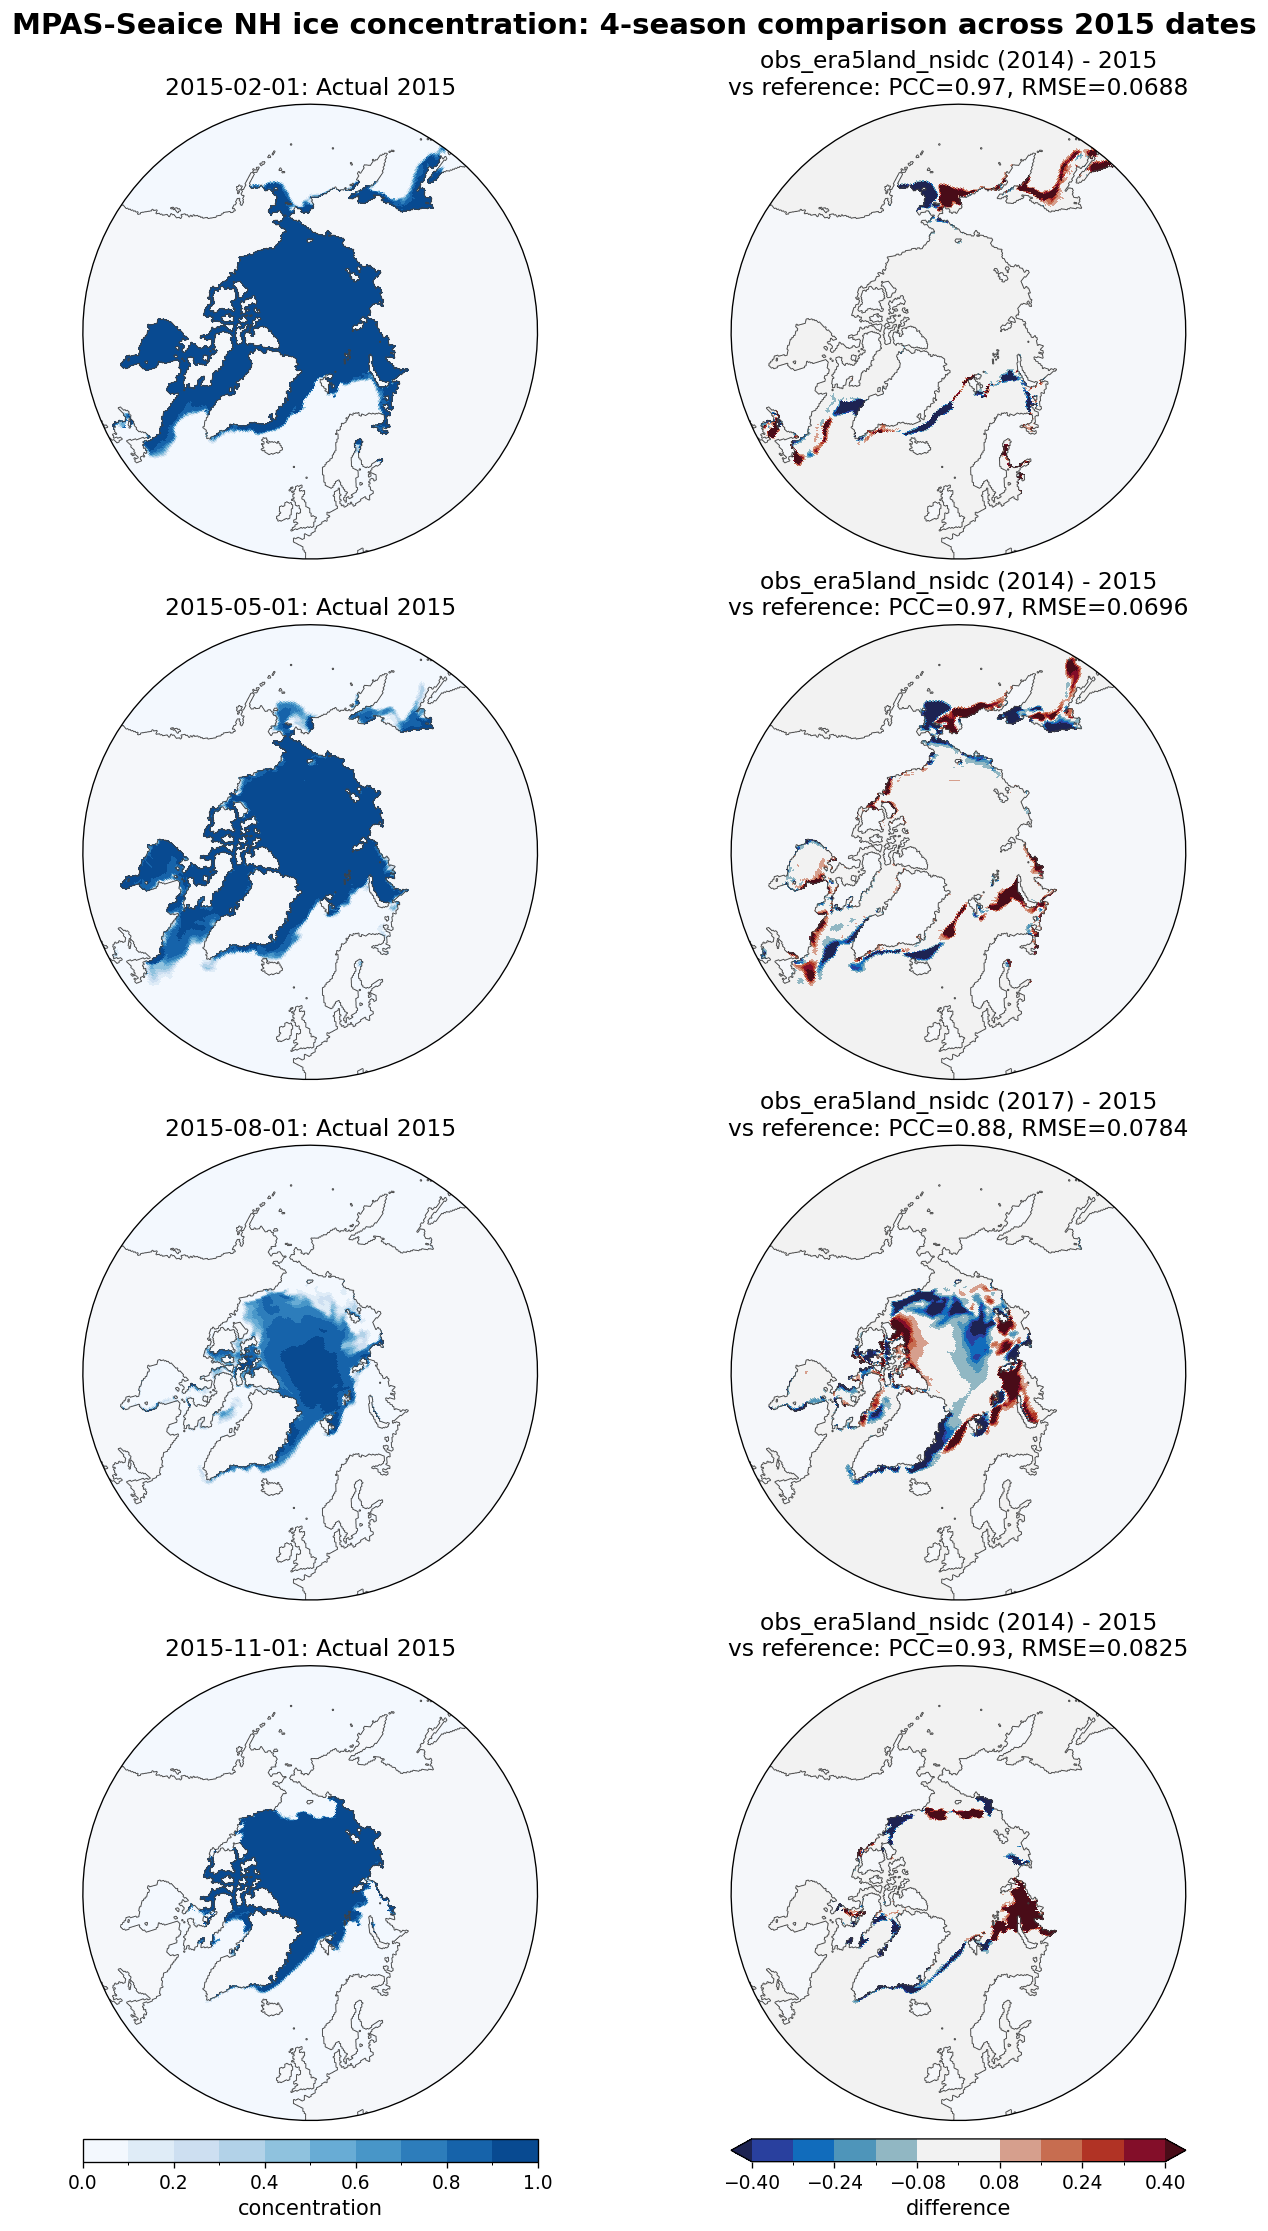

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/obs_era5land_nsidc/figure/mpassi_4seasons_sh_ice_concentration_2015.png


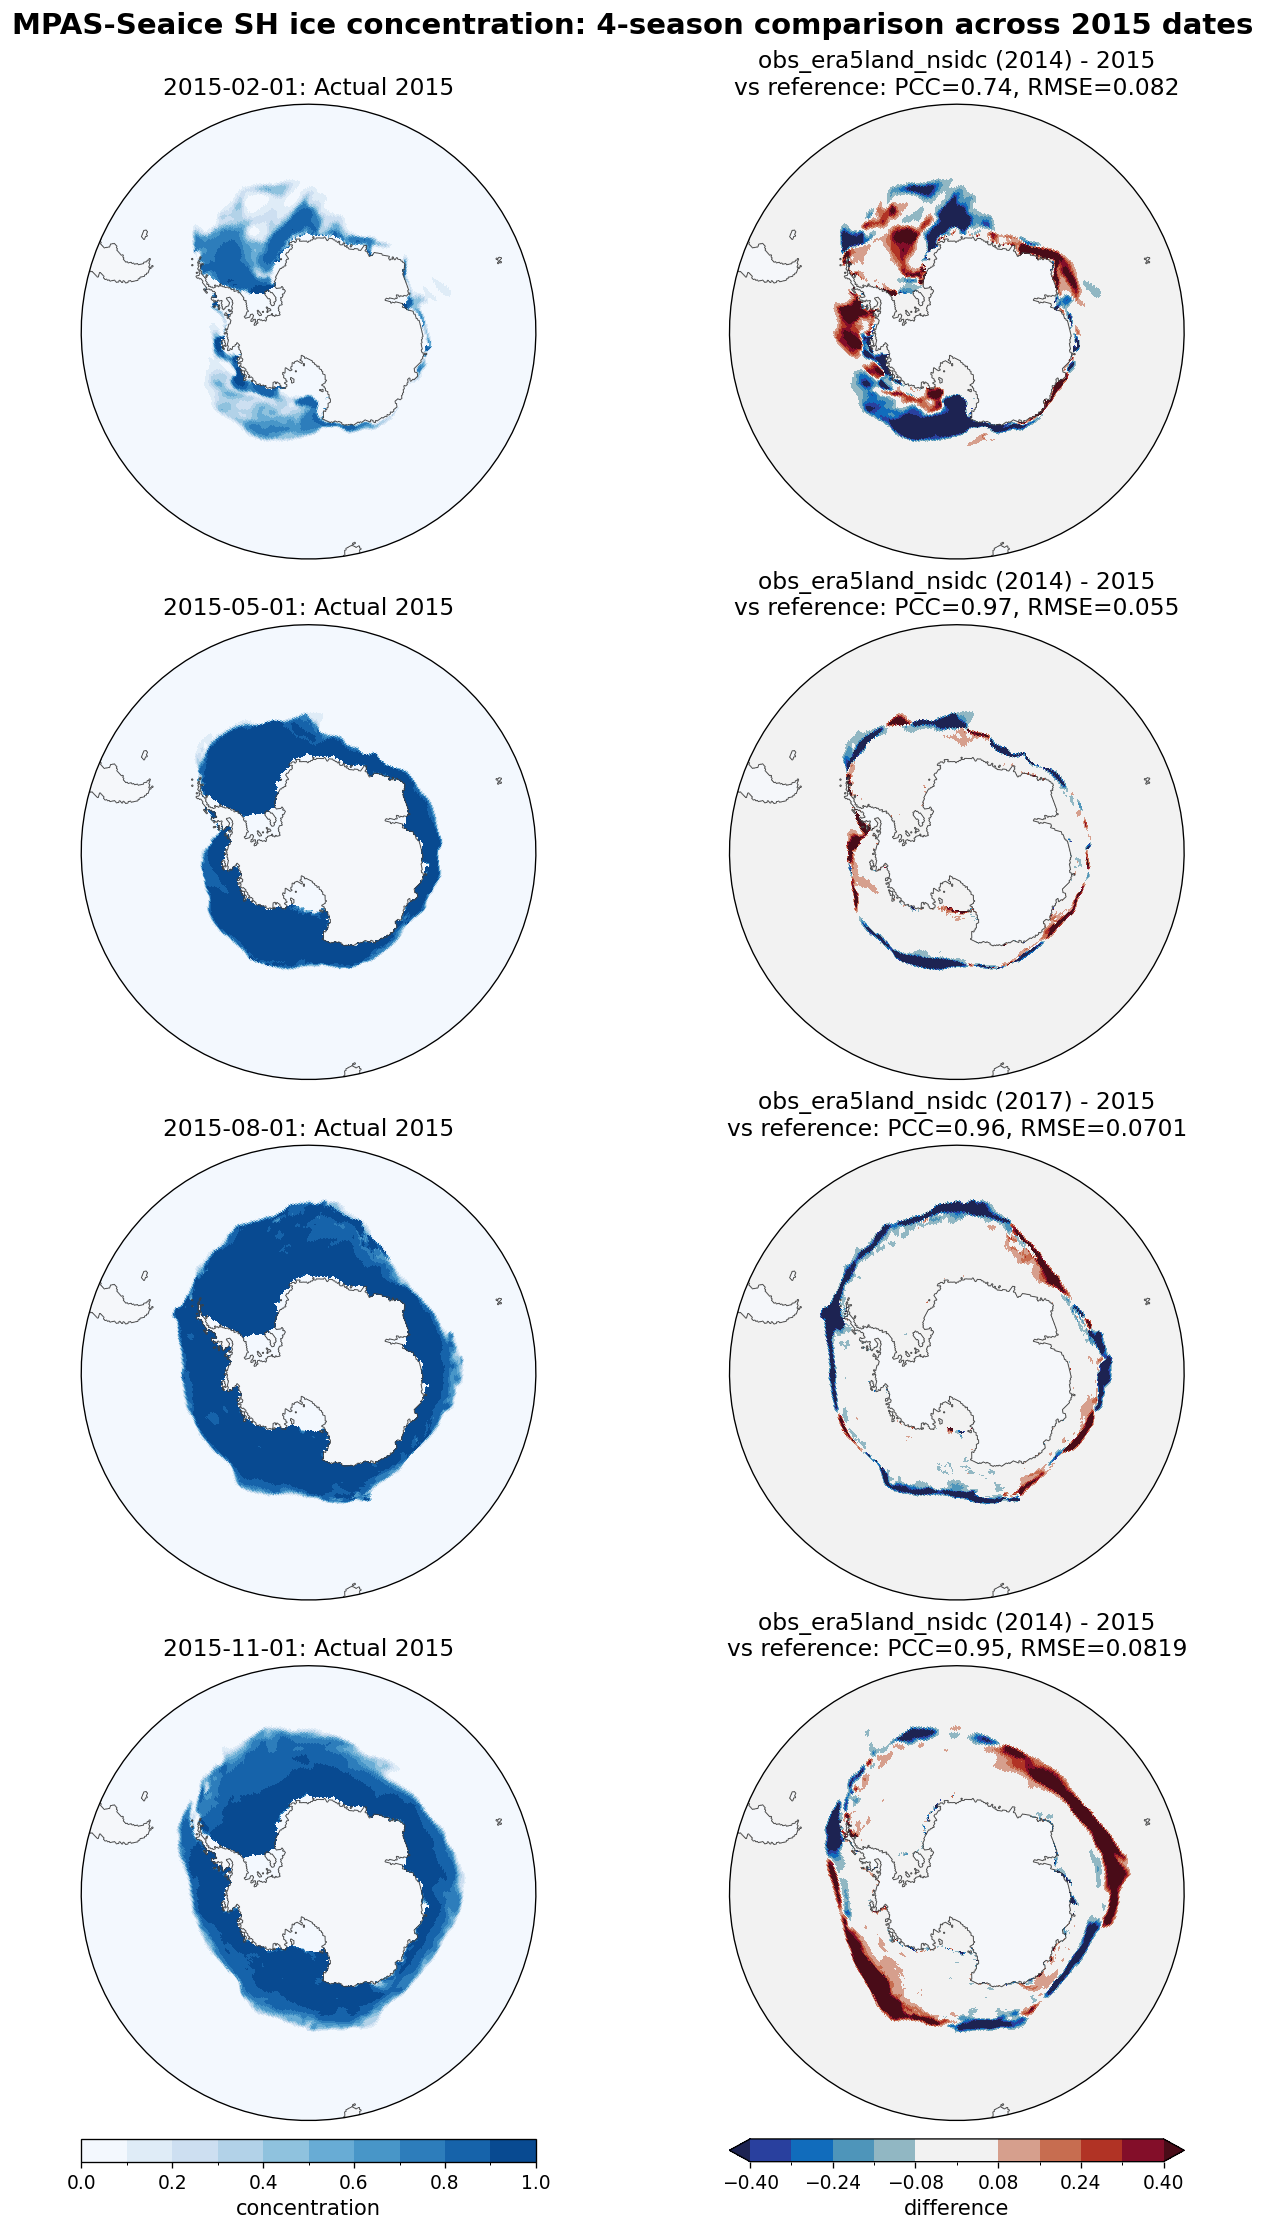

In [4]:
# --- Figure setup ---
FONTSIZE = 14        # panel-title font size; titles, labels, and ticks scale from it
PANEL_SIZE = None    # (width, height) of each panel in inches; None scales with FONTSIZE
DPI = 150            # resolution of the saved PNG
DIFF_LIM = 0.4       # color range of the concentration differences

for hemi_field in ["NH ice concentration", "SH ice concentration"]:
    fig = ice.plot_mpassi_four_seasons(
        hemi_field, TEST_DATES, plans, selections, mpassi_desc,
        box=BOX, cache_dir=CACHE_DIR, diff_lim=DIFF_LIM, fontsize=FONTSIZE, panel_size=PANEL_SIZE,
    )
    ice.save_fig(fig, f"mpassi_4seasons_{ice.slugify(hemi_field)}_2015", DIAG_ROOT, SAVE_DIAG, dpi=DPI)
    plt.show()

## 4. Key findings

Evaluated branch: `obs_era5land_nsidc` (`EVAL_BRANCH`); selected years 2014, 2014, 2017, 2014 for the four
2015 dates.

**Table. Sea-ice concentration of the selected year vs actual 2015** (native mesh; PCC: pattern correlation,
RMSE: root-mean-square difference in concentration).

| Date | Selected year | NH PCC | NH RMSE | SH PCC | SH RMSE |
|---|---|---|---|---|---|
| 2015-02-01 | 2014 | 0.97 | 0.069 | 0.74 | 0.082 |
| 2015-05-01 | 2014 | 0.97 | 0.070 | 0.97 | 0.055 |
| 2015-08-01 | 2017 | 0.88 | 0.078 | 0.96 | 0.070 |
| 2015-11-01 | 2014 | 0.93 | 0.083 | 0.95 | 0.082 |

1. **Differences are concentrated at the ice edge.** The interior pack is nearly identical in winter in both
   hemispheres; differences of +/-0.2-0.4 appear along the marginal ice zone (Bering, Okhotsk, Labrador, and
   Barents seas in the NH; the outer edge in the SH).
2. **The weakest matches are at the summer minima.** NH Aug (PCC 0.88): the 2017 pack differs inside the Arctic
   (lower concentration on the Pacific side, more ice toward the Atlantic), consistent with the -10% ice area
   in `04`. SH Feb (PCC 0.74): the remnant ice in the Weddell and Ross seas differs, consistent with the -14% SH
   area in `04`.
3. **Nov NH has excess ice in the Barents-Kara Sea** in the selected year (2014), the largest single regional
   difference in the NH winter cases.
4. **The standardized anomaly maps (section 2, 2015-02-01)** compare the actual 2015 model state and the
   selected initial condition with the observed NOAA/NSIDC anomaly (the truth). NH: the actual model state
   matches the observed ice-edge anomalies well at box scale (box PCC = 0.96; grid PCC = 0.64), the selected
   year (2014) only partly (box PCC = 0.52; grid 0.29). SH: both match weakly (actual: box 0.66, grid 0.32;
   selected: box 0.69, grid 0.18); the selected year shares the positive Weddell Sea anomaly but has the
   opposite sign in the Ross-Amundsen sector.
